# 02 - Modeling
Notebook ini mendokumentasikan alur pemodelan: validasi, ablation fitur `building_id`, evaluasi, dan (opsional) hyperparameter tuning berbasis **Pipeline**.

Semua logika ada di `scripts/` (`feature_engineering.py`, `preprocess.py`, `train.py`); notebook ini hanya memanggilnya.
Jalankan dari folder `notebooks/` (menu **Run All** agar output tersimpan).

In [1]:
import sys, warnings
sys.path.append("../scripts")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from lightgbm import LGBMClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
                             f1_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split

import train as T

## 1. Muat data & split validasi (80/20, stratified)

In [2]:
X, y = T.load_train("../data/train.csv")
X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_tr.shape, "| Validation:", X_val.shape)
pd.Series(y + 1, name="damage_grade").value_counts(normalize=True).sort_index().plot.bar(
    title="Distribusi target (train)", rot=0)
plt.ylabel("Proporsi"); plt.show()

Train: (426772, 16) | Validation: (106693, 16)


## 2. Ablation: apakah fitur tetangga `building_id` berpengaruh?
Dua pipeline identik (setting ringan: LightGBM 150 pohon, lr 0.1) dibandingkan, dengan dan tanpa `NeighborTargetFeatures`.
Fitur tetangga dihitung **di dalam Pipeline** dengan skema leave-one-out untuk data train, sehingga tidak membocorkan label.

In [3]:
def quick_pipeline(use_id: bool):
    """Pipeline ringan untuk perbandingan cepat (setting sama untuk kedua varian)."""
    pipe = T.build_pipeline(use_id_features=use_id, model_type="lgbm")
    pipe.set_params(classifier=LGBMClassifier(
        n_estimators=150, learning_rate=0.1, num_leaves=63,
        random_state=42, n_jobs=-1, verbose=-1))
    return pipe

rows, probas = [], {}
for name, flag in [("Tanpa fitur ID", False), ("Dengan fitur ID", True)]:
    pipe = quick_pipeline(flag).fit(X_tr, y_tr)
    proba = pipe.predict_proba(X_val)
    probas[name] = proba
    pred = proba.argmax(1)
    rows.append({"Model": name,
                 "Micro F1": f1_score(y_val, pred, average="micro"),
                 "Macro F1": f1_score(y_val, pred, average="macro")})
ablation = pd.DataFrame(rows).set_index("Model").round(4)
ablation

,Micro F1,Macro F1
Model,,
Tanpa fitur ID,0.5786,0.5318
Dengan fitur ID,0.6203,0.5838


### Confusion matrix & classification report (varian dengan fitur ID)

In [4]:
pred = probas["Dengan fitur ID"].argmax(1)
labels = [f"Grade {i}" for i in range(1, 6)]
ConfusionMatrixDisplay.from_predictions(y_val, pred, display_labels=labels,
                                        normalize="true", cmap="Blues", values_format=".2f")
plt.title("Confusion matrix (dinormalisasi per kelas)"); plt.show()
print(classification_report(y_val, pred, target_names=labels))

              precision    recall  f1-score   support

     Grade 1       0.65      0.75      0.69     11034
     Grade 2       0.46      0.40      0.43     12216
     Grade 3       0.48      0.46      0.47     19098
     Grade 4       0.56      0.56      0.56     25738
     Grade 5       0.75      0.78      0.76     38607

    accuracy                           0.62    106693
   macro avg       0.58      0.59      0.58    106693
weighted avg       0.61      0.62      0.62    106693



## 3. Konfigurasi final (`train.py`)
Konfigurasi final memakai LightGBM yang sudah di-tuning (700 pohon, lr 0.05, 127 leaves, subsample 0.8, colsample 0.6, lambda 2) ditambah **bobot probabilitas per kelas** yang dioptimalkan untuk macro F1 pada data validasi.

Hasil dari `python train.py` (lihat `reports/train_log.txt`):

| Setting | Micro F1 | Macro F1 |
|---|---|---|
| Argmax | 0.6243 | 0.5883 |
| + bobot kelas (dipakai untuk submission) | 0.6203 | **0.5934** |

Skor Public Leaderboard Kaggle: **0.59886** (macro F1 pada ~30% data test).

### Feature importance (dari `train.py`)

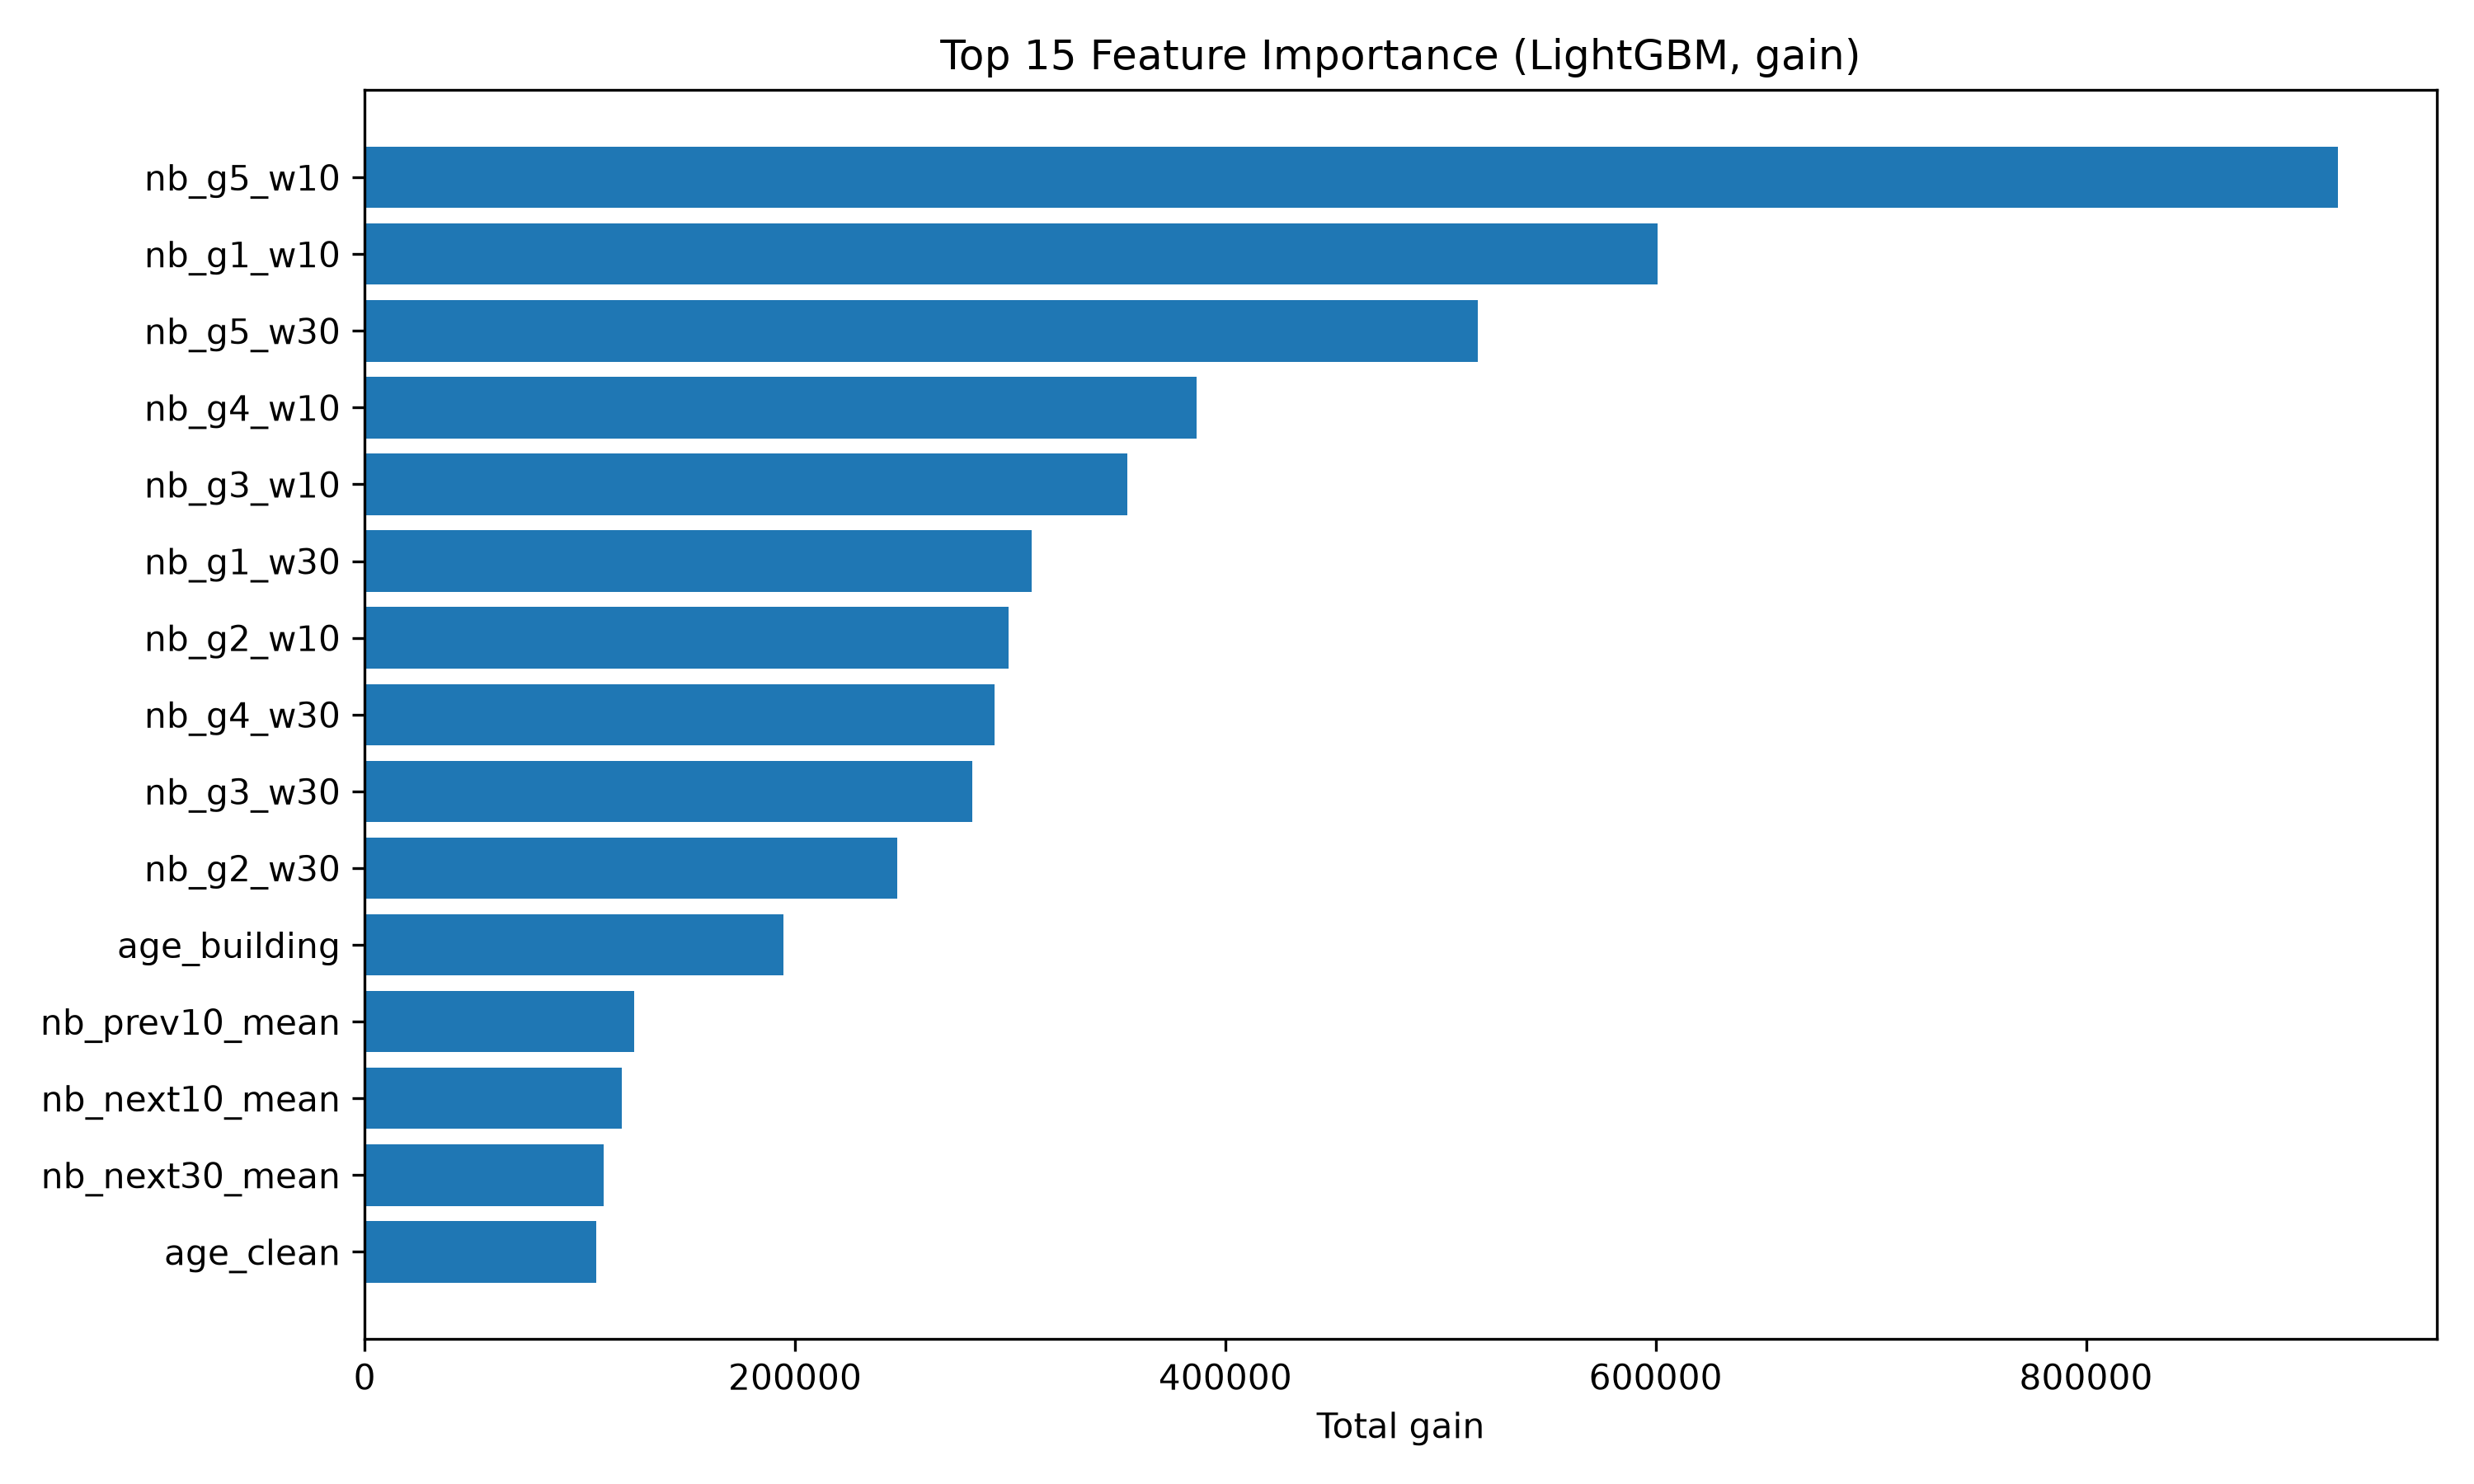

In [5]:
display(Image("../reports/figures/feature_importance.png"))

## 4. (Opsional) Hyperparameter tuning dengan `RandomizedSearchCV` di atas Pipeline
Karena seluruh preprocessing ada di dalam `Pipeline`, tuning dilakukan langsung pada pipeline: setiap fold menghitung ulang fitur (termasuk fitur tetangga) hanya dari data train fold tersebut.
Set `RUN_TUNING = True` untuk menjalankan (memakan waktu cukup lama).

In [6]:
RUN_TUNING = False

if RUN_TUNING:
    base = T.build_pipeline(use_id_features=True, model_type="lgbm")
    base.set_params(classifier__n_estimators=200, classifier__learning_rate=0.1,
                    classifier__subsample_freq=1)
    param_dist = {
        "classifier__num_leaves": [31, 63, 127, 255],
        "classifier__min_child_samples": [20, 40, 80],
        "classifier__colsample_bytree": [0.5, 0.7, 0.9],
        "classifier__subsample": [0.7, 0.8, 1.0],
        "classifier__reg_lambda": [0, 1, 2, 5],
    }
    search = RandomizedSearchCV(
        base, param_dist, n_iter=6, scoring="f1_macro",
        cv=StratifiedKFold(3, shuffle=True, random_state=42),
        random_state=42, n_jobs=1, verbose=2)
    search.fit(X, y)
    print("Best macro F1 (CV):", round(search.best_score_, 4))
    print("Best params:", search.best_params_)
else:
    print("Tuning dilewati (RUN_TUNING=False).")

Tuning dilewati (RUN_TUNING=False).


## 5. Kesimpulan singkat
- Fitur fisik + statistik ward saja memberi macro F1 sekitar 0.53; menambah fitur tetangga `building_id` menaikkannya ke sekitar 0.58-0.59 (lihat tabel ablation di atas).
- Tuning + bobot kelas memberi tambahan kecil, dan skor public (0.59886) konsisten dengan skor validasi, jadi tidak ada tanda overfitting ke validasi.
- Keterbatasan: fitur tetangga memanfaatkan pola ID survei, bukan sifat fisik bangunan, sehingga tidak akan membantu pada gempa baru (lihat README).